# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from IPython.display import display

REPO = os.environ.get("BIGDATA_REPO", "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate")
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__, "shapely:", shapely.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0 shapely: 2.1.2


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [4]:
# 1. Diagnóstico y contrato
# Copias intactas de las entradas: todo lo que sigue trabaja sobre columnas nuevas.
suelo_original = suelo.copy()
territorio_original = territorio.copy()
N_SUELO = len(suelo)
N_TERRITORIO = len(territorio)
print("AGROSAVIA:", suelo.shape, "| DIVIPOLA:", territorio.shape)

def perfil_ausencias(tabla, nombre):
    filas = []
    for columna in tabla.columns:
        valores = tabla[columna]
        limpio = valores.str.strip()
        filas.append({
            "tabla": nombre,
            "columna": columna,
            "tipo": str(valores.dtype),
            "nulos": int(valores.isna().sum()),
            "vacios_tras_strip": int(limpio.eq("").sum()),
            "marcador_ND": int(limpio.str.upper().eq("ND").sum()),
            "distintos": int(valores.nunique(dropna=False)),
        })
    return pd.DataFrame(filas)

perfil = pd.concat([perfil_ausencias(suelo, "agrosavia"),
                    perfil_ausencias(territorio, "divipola")], ignore_index=True)
display(perfil)

CAMPOS_SUELO = ["Secuencial", "Fecha de Análisis", "Departamento", "Municipio", "pH agua:suelo"]
CAMPOS_TERR = ["Código Departamento", "Nombre Departamento", "Código Municipio",
               "Nombre Municipio", "longitud", "Latitud"]
print("Ejemplos AGROSAVIA:")
display(suelo[CAMPOS_SUELO].sample(5, random_state=1))
print("Ejemplos DIVIPOLA:")
display(territorio[CAMPOS_TERR].sample(5, random_state=1))
print("Secuencial repetido:", int(suelo["Secuencial"].duplicated().sum()),
      "→ por eso id_fila se toma de la posición de la fila")

cantidades_iniciales = pd.DataFrame({
    "tabla": ["agrosavia", "divipola"],
    "filas": [N_SUELO, N_TERRITORIO],
    "columnas": [suelo.shape[1], territorio.shape[1]],
})
display(cantidades_iniciales)

AGROSAVIA: (92738, 32) | DIVIPOLA: (1122, 7)


,tabla,columna,tipo,nulos,vacios_tras_strip,marcador_ND,distintos
0,agrosavia,Secuencial,object,0,0,0,92738
1,agrosavia,Fecha de Análisis,object,0,0,0,2388
2,agrosavia,Departamento,object,0,0,0,33
3,agrosavia,Municipio,object,0,2,0,991
4,agrosavia,Cultivo,object,0,0,0,282
5,agrosavia,Estado,object,0,0,0,4
6,agrosavia,Tiempo de establecimiento,object,0,0,0,9
7,agrosavia,Topografia,object,0,0,0,13
8,agrosavia,Drenaje,object,0,0,0,6
9,agrosavia,Riego,object,0,0,0,17


Ejemplos AGROSAVIA:


,Secuencial,Fecha de Análisis,Departamento,Municipio,pH agua:suelo
24794,24793,30/09/2016,TOLIMA,ESPINAL,7.14
6031,6031,19/03/2014,VALLE DEL CAUCA,LA UNIÓN,7.05
63935,63933,29/12/2021,VALLE DEL CAUCA,CALI,6.12
29986,29986,19/12/2016,QUINDÍO,FILANDIA,6.73
59088,59087,17/02/2020,HUILA,NEIVA,5.31


Ejemplos DIVIPOLA:


,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,longitud,Latitud
1032,76,VALLE DEL CAUCA,76520,PALMIRA,"-76,298846","3,531544"
47,05,ANTIOQUIA,05282,FREDONIA,"-75,675072","5,928039"
529,25,CUNDINAMARCA,25592,QUEBRADANEGRA,"-74,48014","5,118076"
154,13,BOLÍVAR,13062,ARROYOHONDO,"-75,019215","10,250075"
258,15,BOYACÁ,15511,PACHAVITA,"-73,396953","5,140065"


Secuencial repetido: 0 → por eso id_fila se toma de la posición de la fila


,tabla,filas,columnas
0,agrosavia,92738,32
1,divipola,1122,7


### Contrato de salida

| Campo de salida | Tipo | Regla de validez | Ausencias |
|---|---|---|---|
| `id_fila` | `Int64` | posición de la fila en esta copia del CSV (0…n-1), única | nunca ausente |
| `fecha_dt` | `datetime64` | `Fecha de Análisis` con formato `%d/%m/%Y` | vacía, `ND` o no interpretable → `NaT` |
| `anio` | `Int64` | año de `fecha_dt` | `<NA>` si `fecha_dt` es `NaT` |
| `ph` | `Float64` | `pH agua:suelo` numérico (coma o punto decimal) | vacío, `ND` o texto como `<3.80` → `<NA>` |
| `ph_valido` | `boolean` | `ph` no ausente y dentro de [0, 14] | `False` si `ph` es `<NA>` |
| `departamento_norm`, `municipio_norm` | `string` | nombre sin tildes, mayúsculas, sin espacios externos ni repetidos | texto vacío → `<NA>` (clave incompleta) |
| `codigo_departamento` | `string` | 2 cifras, desde DIVIPOLA | `<NA>` si no hay enlace |
| `codigo_municipio` | `string` | 5 cifras, desde DIVIPOLA | `<NA>` si no hay enlace |
| `nombre_departamento_divipola`, `nombre_municipio_divipola` | `string` | nombres oficiales DIVIPOLA 2024 | `<NA>` si no hay enlace |
| `longitud_territorial`, `latitud_territorial` | `Float64` | coordenada del municipio en DIVIPOLA, en [−180, 180] y [−90, 90] | `<NA>`; no es la ubicación de la muestra |
| `estado_union` | `string` | `coincide`, `coincide_equivalencia`, `clave_incompleta`, `ambigua`, `sin_correspondencia` | nunca ausente |

**Interpretación:**

Antes de transformar guardé copias intactas de las dos tablas y sus cantidades. Todo se leyó como texto (`dtype=str`, `keep_default_na=False`), así que no hay nulos de pandas: las ausencias aparecen como texto vacío o como `ND`, y por eso las cuento por separado. `Secuencial` no sirve como identificador porque puede repetirse; por eso `id_fila` sale de la posición de la fila. El perfil solo dice cuántos valores faltan, no si los que están son correctos.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [5]:
# 2. Conversión de medidas, fechas y coordenadas (columnas nuevas; originales intactas)
suelo["id_fila"] = pd.array(np.arange(len(suelo)), dtype="Int64")

fecha_txt = suelo["Fecha de Análisis"].str.strip()
suelo["fecha_dt"] = pd.to_datetime(fecha_txt, format="%d/%m/%Y", errors="coerce")
suelo["anio"] = suelo["fecha_dt"].dt.year.astype("Int64")

ph_txt = suelo["pH agua:suelo"].str.strip()
suelo["ph"] = pd.to_numeric(ph_txt.str.replace(",", ".", regex=False), errors="coerce").astype("Float64")
suelo["ph_valido"] = (suelo["ph"].notna() & suelo["ph"].between(0, 14)).astype("boolean")

def controles_conversion(texto, convertido, nombre):
    ausente = texto.eq("") | texto.str.upper().eq("ND")
    fallo = ~ausente & convertido.isna()
    return ausente, fallo, {"campo": nombre, "ausente_vacio_o_ND": int(ausente.sum()),
                            "texto_no_convertible": int(fallo.sum()),
                            "convertidos": int(convertido.notna().sum())}

fecha_aus, fecha_fallo, c_fecha = controles_conversion(fecha_txt, suelo["fecha_dt"], "fecha_dt")
ph_aus, ph_fallo, c_ph = controles_conversion(ph_txt, suelo["ph"], "ph")
c_ph["fuera_de_0_14"] = int((suelo["ph"].notna() & ~suelo["ph"].between(0, 14)).sum())
c_ph["ph_valido"] = int(suelo["ph_valido"].sum())

# DIVIPOLA: solo las coordenadas usan coma decimal
print("Ejemplos de coordenadas originales:")
display(territorio[["longitud", "Latitud"]].head())
lon_txt = territorio["longitud"].str.strip()
lat_txt = territorio["Latitud"].str.strip()
territorio["longitud_territorial"] = pd.to_numeric(lon_txt.str.replace(",", ".", regex=False), errors="coerce").astype("Float64")
territorio["latitud_territorial"] = pd.to_numeric(lat_txt.str.replace(",", ".", regex=False), errors="coerce").astype("Float64")
lon_aus, lon_fallo, c_lon = controles_conversion(lon_txt, territorio["longitud_territorial"], "longitud_territorial")
lat_aus, lat_fallo, c_lat = controles_conversion(lat_txt, territorio["latitud_territorial"], "latitud_territorial")
c_lon["fuera_de_rango"] = int((territorio["longitud_territorial"].notna() & ~territorio["longitud_territorial"].between(-180, 180)).sum())
c_lat["fuera_de_rango"] = int((territorio["latitud_territorial"].notna() & ~territorio["latitud_territorial"].between(-90, 90)).sum())

controles_tipos = pd.DataFrame([c_fecha, c_ph, c_lon, c_lat])
display(controles_tipos)

print("Hasta 5 ejemplos por fallo:")
display(suelo.loc[fecha_fallo, ["id_fila", "Fecha de Análisis"]].head(5))
display(suelo.loc[ph_fallo, ["id_fila", "pH agua:suelo"]].head(5))
display(suelo.loc[suelo["ph"].notna() & ~suelo["ph_valido"], ["id_fila", "pH agua:suelo", "ph"]].head(5))
display(territorio.loc[lon_fallo | lat_fallo | lon_aus | lat_aus,
                       ["Código Municipio", "Nombre Municipio", "longitud", "Latitud"]].head(5))
print("Rango pH:", suelo["ph"].min(), "a", suelo["ph"].max(),
      "| Rango fechas:", suelo["fecha_dt"].min(), "a", suelo["fecha_dt"].max())
assert len(suelo) == N_SUELO and len(territorio) == N_TERRITORIO

Ejemplos de coordenadas originales:


,longitud,Latitud
0,"-75,581775","6,246631"
1,"-75,428739","5,789315"
2,"-76,064304","6,632282"
3,"-75,141346","6,376061"
4,"-75,702188","6,038708"


,campo,ausente_vacio_o_ND,texto_no_convertible,convertidos,fuera_de_0_14,ph_valido,fuera_de_rango
0,fecha_dt,0,0,92738,NaN,NaN,NaN
1,ph,0,11,92727,0.0,92727.0,NaN
2,longitud_territorial,0,0,1122,NaN,NaN,0.0
3,latitud_territorial,0,0,1122,NaN,NaN,0.0


Hasta 5 ejemplos por fallo:


,id_fila,Fecha de Análisis


,id_fila,pH agua:suelo
7282,7282,4..01
46528,46528,>10.00
46530,46530,>10.00
52903,52903,<3.80
56330,56330,<3.80


,id_fila,pH agua:suelo,ph


,Código Municipio,Nombre Municipio,longitud,Latitud


Rango pH: 3.19 a 10.57 | Rango fechas: 2014-01-07 00:00:00 a 2025-09-05 00:00:00


**Interpretación:**

Las conversiones se hicieron en columnas nuevas y no se eliminó ninguna fila. Los valores que no se pudieron convertir (por ejemplo `<3.80`, `>10.00` o `4..01`) quedan como ausentes, pero separados de los que venían vacíos o con `ND`, porque son problemas distintos: uno es un dato censurado o mal digitado y el otro es un dato que no se midió. No reemplacé ausencias por cero. Que una coordenada esté dentro del rango solo indica que es posible, no que sea correcta; además, esa coordenada es del municipio, no de la muestra.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [6]:
# 3. Normalización de nombres y claves
def normalizar(serie):
    return (serie
            .str.normalize("NFKD")                              # separa letra y tilde: Á → A + ´
            .str.replace(r"[̀-ͯ]", "", regex=True)    # quita tildes y diéresis (Ñ → N)
            .str.upper()
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)              # espacios repetidos → uno
            .replace("", pd.NA)
            .astype("string"))

suelo["departamento_norm"] = normalizar(suelo["Departamento"])
suelo["municipio_norm"] = normalizar(suelo["Municipio"])
territorio["departamento_norm"] = normalizar(territorio["Nombre Departamento"])
territorio["municipio_norm"] = normalizar(territorio["Nombre Municipio"])

territorio["codigo_municipio"] = territorio["Código Municipio"].str.strip().str.zfill(5).astype("string")
territorio["codigo_departamento"] = territorio["Código Departamento"].str.strip().str.zfill(2).astype("string")
assert territorio["codigo_municipio"].str.fullmatch(r"\d{5}").all()
assert territorio["codigo_departamento"].str.fullmatch(r"\d{2}").all()
assert territorio["codigo_municipio"].is_unique, "Código Municipio repetido en DIVIPOLA"
assert (territorio["codigo_municipio"].str[:2] == territorio["codigo_departamento"]).all()

CLAVE = ["departamento_norm", "municipio_norm"]
territorio["clave_completa"] = territorio[CLAVE].notna().all(axis=1)
territorio["clave_ambigua"] = territorio["clave_completa"] & territorio.duplicated(CLAVE, keep=False)
claves_ambiguas = territorio.loc[territorio["clave_ambigua"],
    ["codigo_municipio", "Nombre Departamento", "Nombre Municipio", *CLAVE]]
claves_ambiguas.to_csv(OUT + "/claves_ambiguas.csv", index=False)

# Qué se pierde al normalizar: nombres distintos que quedan iguales
perdidas = (territorio.groupby(CLAVE, dropna=True)["Nombre Municipio"].nunique()
            .loc[lambda s: s > 1])
print("Claves vacías en DIVIPOLA:", int((~territorio["clave_completa"]).sum()))
print("Claves ambiguas en DIVIPOLA:", len(claves_ambiguas))
print("Nombres distintos que colapsan tras normalizar:", len(perdidas))
print("Claves incompletas en AGROSAVIA:", int(suelo[CLAVE].isna().any(axis=1).sum()))

dimension = territorio.loc[territorio["clave_completa"] & ~territorio["clave_ambigua"], [
    *CLAVE, "codigo_departamento", "codigo_municipio",
    "Nombre Departamento", "Nombre Municipio", "longitud_territorial", "latitud_territorial",
]].rename(columns={"Nombre Departamento": "nombre_departamento_divipola",
                   "Nombre Municipio": "nombre_municipio_divipola"})
assert not dimension.duplicated(CLAVE).any()
assert dimension["codigo_municipio"].is_unique
print("Dimensión territorial (claves completas y no ambiguas):", len(dimension), "de", N_TERRITORIO)
display(claves_ambiguas)

Claves vacías en DIVIPOLA: 0
Claves ambiguas en DIVIPOLA: 0
Nombres distintos que colapsan tras normalizar: 0
Claves incompletas en AGROSAVIA: 2
Dimensión territorial (claves completas y no ambiguas): 1122 de 1122


,codigo_municipio,Nombre Departamento,Nombre Municipio,departamento_norm,municipio_norm


**Interpretación:**

La normalización quita tildes, pasa a mayúsculas y limpia espacios, pero el texto original queda en sus columnas. Su costo es que la `Ñ` se vuelve `N` y dos nombres que solo se diferencien en una tilde quedarían iguales; por eso reviso si alguna clave quedó repetida. Los códigos DIVIPOLA se guardan como texto (5 y 2 cifras) para no perder los ceros iniciales. La dimensión solo incluye claves completas y no ambiguas, y las ambiguas se exportan a `claves_ambiguas.csv` en lugar de resolverse con `drop_duplicates`.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [7]:
# 4. Integración y equivalencias justificadas
integrado = suelo.merge(dimension, on=CLAVE, how="left", validate="many_to_one", indicator="union_merge")
assert len(integrado) == N_SUELO and integrado["id_fila"].is_unique

clave_incompleta = integrado[CLAVE].isna().any(axis=1)          # una clave con NA nunca coincide (la dimensión no tiene NA)
clave_es_ambigua = integrado.set_index(CLAVE).index.isin(claves_ambiguas.set_index(CLAVE).index)
integrado["estado_union_inicial"] = np.select(
    [integrado["union_merge"].eq("both"), clave_incompleta, clave_es_ambigua],
    ["coincide", "clave_incompleta", "ambigua"], default="sin_correspondencia")
integrado["estado_union_inicial"] = integrado["estado_union_inicial"].astype("string")

def cobertura(estado, etiqueta):
    t = estado.value_counts().rename("analisis").to_frame()
    t["porcentaje"] = (t["analisis"] / N_SUELO * 100).round(2)
    t["momento"] = etiqueta
    return t.reset_index()

cobertura_antes = cobertura(integrado["estado_union_inicial"], "antes")
display(cobertura_antes)

sin_corr = (integrado[integrado["estado_union_inicial"].eq("sin_correspondencia")]
            .groupby(["Departamento", "Municipio", *CLAVE], dropna=False).size()
            .rename("analisis").reset_index().sort_values("analisis", ascending=False))
print("Nombres sin correspondencia (hasta 10 con más análisis):")
display(sin_corr.head(10))

# Equivalencias: solo cuando el nombre coincide al ignorar puntuación y espacios,
# dentro de la dimensión, y con un único candidato. Lo demás queda pendiente.
def compacta(serie):
    return serie.str.replace(r"[^A-Z0-9]", "", regex=True)

dimension_comp = dimension.assign(dep_c=compacta(dimension["departamento_norm"]),
                                  mun_c=compacta(dimension["municipio_norm"]))
candidatos = sin_corr.assign(dep_c=compacta(sin_corr["departamento_norm"]),
                             mun_c=compacta(sin_corr["municipio_norm"]))
candidatos = candidatos.merge(dimension_comp[["dep_c", "mun_c", "codigo_municipio",
                                              "nombre_departamento_divipola", "nombre_municipio_divipola"]],
                              on=["dep_c", "mun_c"], how="left")
n_cand = candidatos.groupby(CLAVE, dropna=False)["codigo_municipio"].transform("count")
candidatos["decision"] = np.where(candidatos["codigo_municipio"].notna() & n_cand.eq(1),
                                  "aplicar", "pendiente")
candidatos["evidencia"] = np.where(
    candidatos["decision"].eq("aplicar"),
    "Mismo nombre DIVIPOLA al ignorar solo puntuación y espacios (" +
    candidatos["nombre_departamento_divipola"].fillna("") + " / " +
    candidatos["nombre_municipio_divipola"].fillna("") + ")",
    "Sin candidato único verificable en DIVIPOLA; requiere revisión documental")
equivalencias = candidatos[["Departamento", "Municipio", *CLAVE, "codigo_municipio",
                            "evidencia", "decision", "analisis"]].rename(
    columns={"codigo_municipio": "codigo_propuesto"}).drop_duplicates(CLAVE)
display(equivalencias.head(15))

aplicar = (equivalencias[equivalencias["decision"].eq("aplicar")][[*CLAVE, "codigo_propuesto"]]
           .merge(dimension.drop(columns=CLAVE), left_on="codigo_propuesto",
                  right_on="codigo_municipio", how="left", validate="many_to_one")
           .drop(columns="codigo_propuesto"))
COLS_DIM = ["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
            "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial"]
integrado = integrado.merge(aplicar, on=CLAVE, how="left", validate="many_to_one", suffixes=("", "_eq"))
usar_eq = integrado["estado_union_inicial"].eq("sin_correspondencia") & integrado["codigo_municipio_eq"].notna()
for c in COLS_DIM:
    integrado[c] = integrado[c].where(~usar_eq, integrado[c + "_eq"])
integrado = integrado.drop(columns=[c + "_eq" for c in COLS_DIM])
integrado["estado_union"] = integrado["estado_union_inicial"].mask(usar_eq, "coincide_equivalencia").astype("string")

assert len(integrado) == N_SUELO
assert integrado["id_fila"].is_unique and set(integrado["id_fila"]) == set(suelo["id_fila"])
cobertura_despues = cobertura(integrado["estado_union"], "despues")
display(pd.concat([cobertura_antes, cobertura_despues], ignore_index=True))
asociados = integrado["codigo_municipio"].notna()
print(f"Cobertura del enlace: antes {integrado['estado_union_inicial'].eq('coincide').mean():.2%}"
      f" → después {asociados.mean():.2%} de {N_SUELO:,} análisis")

,estado_union_inicial,analisis,porcentaje,momento
0,coincide,90600,97.69,antes
1,sin_correspondencia,2136,2.3,antes
2,clave_incompleta,2,0.0,antes


Nombres sin correspondencia (hasta 10 con más análisis):


,Departamento,Municipio,departamento_norm,municipio_norm,analisis
28,NORTE DE SANTANDER,CÚCUTA,NORTE DE SANTANDER,CUCUTA,1095
36,VALLE DEL CAUCA,CALI,VALLE DEL CAUCA,CALI,461
11,CAUCA,SOTARA,CAUCA,SOTARA,188
22,META,FUENTEDEORO,META,FUENTEDEORO,96
24,META,SAN LUIS DE CUBARRAL,META,SAN LUIS DE CUBARRAL,70
10,CAUCA,PIENDAMÓ,CAUCA,PIENDAMO,46
34,TOLIMA,ARMERO GUAYABAL,TOLIMA,ARMERO GUAYABAL,44
26,NARIÑO,CUASPÚD,NARINO,CUASPUD,42
33,SUCRE,TOLÚ VIEJO,SUCRE,TOLU VIEJO,11
4,BOYACÁ,ESPINO,BOYACA,ESPINO,10


,Departamento,Municipio,departamento_norm,municipio_norm,codigo_propuesto,evidencia,decision,analisis
0,NORTE DE SANTANDER,CÚCUTA,NORTE DE SANTANDER,CUCUTA,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,1095
1,VALLE DEL CAUCA,CALI,VALLE DEL CAUCA,CALI,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,461
2,CAUCA,SOTARA,CAUCA,SOTARA,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,188
3,META,FUENTEDEORO,META,FUENTEDEORO,50287,Mismo nombre DIVIPOLA al ignorar solo puntuaci...,aplicar,96
4,META,SAN LUIS DE CUBARRAL,META,SAN LUIS DE CUBARRAL,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,70
5,CAUCA,PIENDAMÓ,CAUCA,PIENDAMO,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,46
6,TOLIMA,ARMERO GUAYABAL,TOLIMA,ARMERO GUAYABAL,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,44
7,NARIÑO,CUASPÚD,NARINO,CUASPUD,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,42
8,SUCRE,TOLÚ VIEJO,SUCRE,TOLU VIEJO,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,11
9,BOYACÁ,ESPINO,BOYACA,ESPINO,<NA>,Sin candidato único verificable en DIVIPOLA; r...,pendiente,10


,estado_union_inicial,analisis,porcentaje,momento,estado_union
0,coincide,90600,97.69,antes,<NA>
1,sin_correspondencia,2136,2.3,antes,<NA>
2,clave_incompleta,2,0.0,antes,<NA>
3,<NA>,90600,97.69,despues,coincide
4,<NA>,2038,2.2,despues,sin_correspondencia
5,<NA>,98,0.11,despues,coincide_equivalencia
6,<NA>,2,0.0,despues,clave_incompleta


Cobertura del enlace: antes 97.69% → después 97.80% de 92,738 análisis


**Interpretación:**

La unión es `left` con `validate="many_to_one"`, así que cada análisis conserva una sola fila y el `id_fila` no se pierde ni se repite. Distingo cuatro estados: coincide, clave incompleta (por ejemplo, municipio vacío), ambigua y sin correspondencia. Solo apliqué una equivalencia cuando el nombre coincide con un único municipio de DIVIPOLA al ignorar puntuación y espacios (como `BOGOTÁ D.C.` frente a `BOGOTÁ, D.C.`). Los demás casos quedan en `equivalencias.csv` como pendientes; no los asigné por parecido. La cobertura que muestro es la del enlace (qué porcentaje de análisis tiene municipio), no la del territorio.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [8]:
# 5. Resumen territorial y límites
integrado["ph_para_media"] = integrado["ph"].where(integrado["ph_valido"].fillna(False))
asociados = integrado["codigo_municipio"].notna()

resumen_municipal = (integrado[asociados]
    .groupby("codigo_municipio", dropna=False)
    .agg(total_analisis=("id_fila", "size"),
         ph_validos=("ph_valido", "sum"),
         media_ph=("ph_para_media", "mean"))
    .reset_index())
resumen_municipal["ph_validos"] = resumen_municipal["ph_validos"].astype("Int64")
resumen_municipal["media_ph"] = resumen_municipal["media_ph"].astype("Float64")

no_asociados = (integrado[~asociados].groupby("estado_union").size()
                .rename("analisis").reset_index())
conciliacion = pd.DataFrame({
    "concepto": ["entrada", "asociados (suma del resumen)", "no asociados"],
    "analisis": [N_SUELO, int(resumen_municipal["total_analisis"].sum()), int(no_asociados["analisis"].sum())],
})
assert conciliacion.loc[1, "analisis"] + conciliacion.loc[2, "analisis"] == N_SUELO
display(conciliacion)
display(no_asociados)
print("Municipios con análisis:", len(resumen_municipal),
      "| sin pH válido (media ausente):", int(resumen_municipal["media_ph"].isna().sum()),
      "| asociados sin coordenadas:", int((asociados & integrado["longitud_territorial"].isna()).sum()))

top = resumen_municipal.merge(dimension[["codigo_municipio", "nombre_departamento_divipola",
                                         "nombre_municipio_divipola"]], on="codigo_municipio", how="left")
display(top.sort_values("total_analisis", ascending=False).head(10))
anios = integrado["anio"].value_counts().sort_index()
print("Hallazgo 1 · municipio con más análisis:", top.loc[top["total_analisis"].idxmax(), "nombre_municipio_divipola"],
      int(top["total_analisis"].max()))
print("Hallazgo 2 · análisis sin municipio:", int((~asociados).sum()), f"({(~asociados).mean():.2%})")
print("Hallazgo 3 · años con análisis:", anios.index.min(), "a", anios.index.max(),
      "| fuera de 2024 (año del catálogo):", int(integrado["anio"].ne(2024).fillna(True).sum()))

,concepto,analisis
0,entrada,92738
1,asociados (suma del resumen),90698
2,no asociados,2040


,estado_union,analisis
0,clave_incompleta,2
1,sin_correspondencia,2038


Municipios con análisis: 1039 | sin pH válido (media ausente): 0 | asociados sin coordenadas: 0


,codigo_municipio,total_analisis,ph_validos,media_ph,nombre_departamento_divipola,nombre_municipio_divipola
643,50001,2165,2165,5.088592,META,VILLAVICENCIO
601,44035,1645,1645,7.993861,LA GUAJIRA,ALBANIA
968,76520,1353,1353,7.045959,VALLE DEL CAUCA,PALMIRA
663,50573,1339,1339,5.088143,META,PUERTO LÓPEZ
728,52835,1050,1050,5.472151,NARIÑO,SAN ANDRÉS DE TUMACO
911,73268,1050,1050,6.708851,TOLIMA,ESPINAL
662,50568,1017,1017,5.08005,META,PUERTO GAITÁN
409,23162,979,979,6.50959,CÓRDOBA,CERETÉ
712,52540,818,818,6.603984,NARIÑO,POLICARPA
817,68235,813,812,5.207462,SANTANDER,EL CARMEN DE CHUCURÍ


Hallazgo 1 · municipio con más análisis: VILLAVICENCIO 2165
Hallazgo 2 · análisis sin municipio: 2040 (2.20%)
Hallazgo 3 · años con análisis: 2014 a 2025 | fuera de 2024 (año del catálogo): 89092


**Interpretación:**

La conciliación cuadra: análisis asociados + no asociados = total de la entrada. Los municipios sin pH válido se conservan con media ausente, y los análisis sin municipio quedan en un control aparte en lugar de eliminarse. Un análisis asociado sin coordenadas conserva su código: la coordenada no hace falta para el enlace.

Límites: DIVIPOLA es de 2024, pero hay análisis desde 2014, así que un municipio creado o renombrado en ese tiempo puede no coincidir. El resumen describe las muestras que llegaron al laboratorio, no una distribución representativa de los suelos de cada municipio.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [9]:
municipios = gpd.read_file(
    "zip://" + RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [11]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [12]:
# 6. CRS y calidad geométrica (sobre copias)
def diagnostico_geometrias(gdf, nombre):
    geom = gdf.geometry
    ausente = geom.isna()
    vacia = ~ausente & geom.is_empty
    invalida = ~ausente & ~vacia & ~geom.is_valid
    print(f"{nombre}: {len(gdf)} entidades | CRS {gdf.crs} | extensión {np.round(gdf.total_bounds, 4)}")
    print("  tipos:", geom.geom_type.value_counts(dropna=False).to_dict())
    print(f"  ausentes {int(ausente.sum())} | vacías {int(vacia.sum())} | inválidas {int(invalida.sum())}")
    return ausente, vacia, invalida

# DANE
mun = municipios.copy()
mun_aus, mun_vac, mun_inv = diagnostico_geometrias(mun, "DANE municipios")
codigo_dane = mun["mpio_cdpmp"].astype(str).str.strip()
print("  mpio_cdpmp de 5 cifras:", bool(codigo_dane.str.fullmatch(r"\d{5}").all()),
      "| único:", codigo_dane.is_unique, "| se esperaban 1.122 →", len(mun))
apartadas_dane = mun.loc[mun_aus | mun_vac, ["mpio_cdpmp"]].assign(motivo="ausente o vacía")
print("  códigos con inválidas:", mun.loc[mun_inv, "mpio_cdpmp"].tolist()[:10])

mun_rep = mun.loc[~(mun_aus | mun_vac)].copy()
wkb_antes = mun_rep.loc[mun_inv].geometry.to_wkb()
mun_rep.loc[mun_inv, "geometry"] = mun_rep.loc[mun_inv].geometry.make_valid()
print("  reparadas con make_valid:", int((wkb_antes != mun_rep.loc[mun_inv].geometry.to_wkb()).sum()),
      "| tipos tras reparar:", mun_rep.loc[mun_inv].geometry.geom_type.value_counts().to_dict())

def solo_poligonos(geom):
    # make_valid puede devolver GeometryCollection: se conservan sus partes poligonales
    if geom.geom_type in ("Polygon", "MultiPolygon"):
        return geom
    partes = [p for p in shapely.get_parts(geom) if p.geom_type in ("Polygon", "MultiPolygon")]
    return shapely.union_all(partes) if partes else None

mun_rep["geometry"] = mun_rep.geometry.apply(solo_poligonos)
no_poligonal = mun_rep.geometry.isna() | mun_rep.geometry.is_empty
apartadas_dane = pd.concat([apartadas_dane, mun_rep.loc[no_poligonal, ["mpio_cdpmp"]].assign(
    motivo="sin componente poligonal tras make_valid")], ignore_index=True)
municipios_validos = mun_rep.loc[~no_poligonal].set_geometry("geometry")
assert municipios_validos.is_valid.all()
print("municipios_validos:", len(municipios_validos), "| apartados:", len(apartadas_dane))

# IGAC
cap = capacidad.copy()
if cap.crs is None:
    # GeoJSON (RFC 7946) siempre está en WGS84 y la consulta pidió outSR=4326: se declara, no se transforma
    cap = cap.set_crs(epsg=4326)
cap_aus, cap_vac, cap_inv = diagnostico_geometrias(cap, "IGAC capacidad")
print("  se esperaban 5 →", len(cap))
cap["id_igac"] = np.arange(len(cap))
cap_rep = cap.loc[~(cap_aus | cap_vac)].copy()
cap_rep.loc[cap_inv, "geometry"] = cap_rep.loc[cap_inv].geometry.make_valid()
cap_rep["geometry"] = cap_rep.geometry.apply(solo_poligonos)
capacidad_valida = cap_rep.loc[~(cap_rep.geometry.isna() | cap_rep.geometry.is_empty)].set_geometry("geometry")
assert capacidad_valida.is_valid.all()
print("capacidad_valida:", len(capacidad_valida))

control_geometrias = pd.DataFrame([
    {"capa": "dane_municipios", "crs": str(municipios.crs), "entidades": len(municipios),
     "ausentes": int(mun_aus.sum()), "vacias": int(mun_vac.sum()), "invalidas": int(mun_inv.sum()),
     "aptas": len(municipios_validos)},
    {"capa": "igac_capacidad", "crs": str(cap.crs), "entidades": len(capacidad),
     "ausentes": int(cap_aus.sum()), "vacias": int(cap_vac.sum()), "invalidas": int(cap_inv.sum()),
     "aptas": len(capacidad_valida)},
])
display(control_geometrias)

DANE municipios: 1122 entidades | CRS EPSG:4326 | extensión [-81.7356  -4.2294 -66.8472  13.3947]
  tipos: {'Polygon': 1113, 'MultiPolygon': 9}
  ausentes 0 | vacías 0 | inválidas 0
  mpio_cdpmp de 5 cifras: True | único: True | se esperaban 1.122 → 1122
  códigos con inválidas: []
  reparadas con make_valid: 0 | tipos tras reparar: {}
municipios_validos: 1122 | apartados: 0
IGAC capacidad: 5 entidades | CRS EPSG:4326 | extensión [-74.2898   4.4868 -74.1371   4.6861]
  tipos: {'Polygon': 5}
  ausentes 0 | vacías 0 | inválidas 0
  se esperaban 5 → 5
capacidad_valida: 5


,capa,crs,entidades,ausentes,vacias,invalidas,aptas
0,dane_municipios,EPSG:4326,1122,0,0,0,1122
1,igac_capacidad,EPSG:4326,5,0,0,0,5


**Interpretación:**

Los polígonos DANE vienen en coordenadas geográficas (MAGNA-SIRGAS) y la muestra IGAC en WGS84. Las dos se miden en grados. `set_crs` solo declara qué sistema tiene una capa sin mover las coordenadas; `to_crs` sí las transforma, y por eso solo lo uso más adelante para medir áreas. Las geometrías inválidas se repararon con `make_valid()` sobre una copia, conservando únicamente las partes poligonales y registrando lo que se apartó. La clave para unir es `mpio_cdpmp` (5 cifras), no `mpio_ccdgo`, que solo es el código dentro del departamento.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Departamento del mapa: 15 | año elegido (más análisis allí): 2015
Polígonos aptos: 1122 | con resumen: 506 | sin resumen: 616
Códigos del resumen sin geometría: 0 | análisis en ellos: 0


,codigo_municipio,total_analisis,ph_validos,media_ph,anio


,concepto,analisis
0,análisis 2015 asociados,12330
1,en el mapa,12330
2,sin geometría,0


Área total de polígonos aptos (millones de ha): 113.88


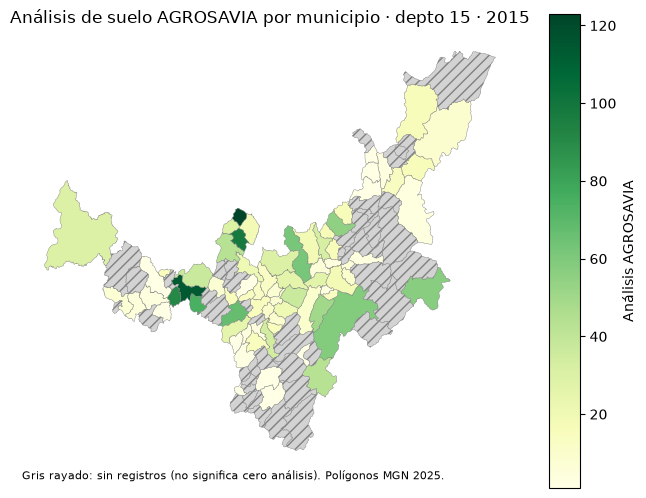

In [13]:
# 7. Tabla + polígonos, área y mapa
DEPARTAMENTO_MAPA = "15"   # Boyacá; cámbialo si quieres otro departamento
asociados = integrado["codigo_municipio"].notna()
en_depto = asociados & integrado["codigo_municipio"].str[:2].eq(DEPARTAMENTO_MAPA).fillna(False)
if not en_depto.any():
    DEPARTAMENTO_MAPA = integrado.loc[asociados, "codigo_municipio"].str[:2].value_counts().index[0]
    en_depto = asociados & integrado["codigo_municipio"].str[:2].eq(DEPARTAMENTO_MAPA).fillna(False)
ANIO = int(integrado.loc[en_depto, "anio"].value_counts().idxmax())
print("Departamento del mapa:", DEPARTAMENTO_MAPA, "| año elegido (más análisis allí):", ANIO)

resumen_anual = (integrado[asociados & integrado["anio"].eq(ANIO).fillna(False)]
    .groupby("codigo_municipio")
    .agg(total_analisis=("id_fila", "size"),
         ph_validos=("ph_valido", "sum"),
         media_ph=("ph_para_media", "mean"))
    .reset_index())
resumen_anual["anio"] = pd.array([ANIO] * len(resumen_anual), dtype="Int64")
resumen_anual["ph_validos"] = resumen_anual["ph_validos"].astype("Int64")
resumen_anual["media_ph"] = resumen_anual["media_ph"].astype("Float64")
resumen_anual["codigo_municipio"] = resumen_anual["codigo_municipio"].astype("string")

municipios_validos["codigo_municipio"] = municipios_validos["mpio_cdpmp"].astype(str).str.strip().astype("string")
assert municipios_validos["codigo_municipio"].is_unique and resumen_anual["codigo_municipio"].is_unique
mapa_municipal = municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left",
                                          validate="one_to_one", indicator=True)
assert len(mapa_municipal) == len(municipios_validos)
assert isinstance(mapa_municipal, gpd.GeoDataFrame) and mapa_municipal.crs == municipios_validos.crs

sin_resumen = mapa_municipal["_merge"].eq("left_only")
sin_geometria = resumen_anual[~resumen_anual["codigo_municipio"].isin(municipios_validos["codigo_municipio"])]
print("Polígonos aptos:", len(municipios_validos), "| con resumen:", int((~sin_resumen).sum()),
      "| sin resumen:", int(sin_resumen.sum()))
print("Códigos del resumen sin geometría:", len(sin_geometria),
      "| análisis en ellos:", int(sin_geometria["total_analisis"].sum()))
display(sin_geometria)
conciliacion_mapa = pd.DataFrame({
    "concepto": [f"análisis {ANIO} asociados", "en el mapa", "sin geometría"],
    "analisis": [int(resumen_anual["total_analisis"].sum()),
                 int(mapa_municipal["total_analisis"].sum()),
                 int(sin_geometria["total_analisis"].sum())]})
assert conciliacion_mapa.loc[1, "analisis"] + conciliacion_mapa.loc[2, "analisis"] == conciliacion_mapa.loc[0, "analisis"]
display(conciliacion_mapa)

# Área en una proyección métrica (EPSG:9377, origen nacional): los grados no son unidades de superficie
mapa_m = mapa_municipal.to_crs(epsg=9377)
mapa_municipal["area_ha"] = (mapa_m.geometry.area / 10000).values
print("Área total de polígonos aptos (millones de ha):", round(mapa_municipal["area_ha"].sum() / 1e6, 2))

depto = mapa_municipal[mapa_municipal["codigo_municipio"].str[:2].eq(DEPARTAMENTO_MAPA)]
fig, ax = plt.subplots(figsize=(8, 8))
depto.plot(column="total_analisis", ax=ax, legend=True, cmap="YlGn", edgecolor="grey", linewidth=0.3,
           legend_kwds={"label": "Análisis AGROSAVIA"},
           missing_kwds={"color": "lightgrey", "hatch": "///", "label": "Sin registros"})
ax.set_title(f"Análisis de suelo AGROSAVIA por municipio · depto {DEPARTAMENTO_MAPA} · {ANIO}")
ax.set_axis_off()
ax.text(0, -0.02, "Gris rayado: sin registros (no significa cero análisis). Polígonos MGN 2025.",
        transform=ax.transAxes, fontsize=8)
plt.savefig(OUT + "/mapa_analisis.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

El resumen del año elegido se unió a los polígonos con `validate="one_to_one"`, y se conservaron todos los polígonos aptos. Los municipios sin resumen quedan en gris rayado; eso no significa cero análisis, sino que no hay registros asociados ese año. Los códigos del resumen que no tienen polígono se muestran y se concilian aparte. El área se calculó después de proyectar a EPSG:9377, porque en grados el área no corresponde a hectáreas. El catálogo DIVIPOLA es de 2024 y los polígonos son de 2025, así que un cambio de límites entre versiones puede dejar códigos sin pareja. La media de pH describe solo las muestras disponibles, no todo el suelo del municipio.

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

Atributos IGAC conservados: ['Descripcio']
municipios_m inválidas tras to_crs: 0
capacidad_m inválidas tras to_crs: 0
Tipos resultantes: {'Polygon': 5, 'MultiPolygon': 4}
Contactos de área cero (líneas/puntos): 0
Piezas: 9 | área total (ha): 4545.23
IGAC: suma de áreas 4,545.23 ha vs área de la unión 4,545.23 ha → solapamiento -0.00 ha


,id_igac,area_original_ha,area_intersectada_ha,fuera_de_municipios_ha,dentro_de_municipios
0,0,1597.896924,1597.896924,9.322321e-12,True
1,1,359.443210,359.443210,1.136868e-13,True
2,2,1288.865623,1288.865623,5.229595e-12,True
3,3,876.420920,876.420920,5.684342e-13,True
4,4,422.606857,422.606857,0.000000e+00,True


Municipios con área intersectada: 5


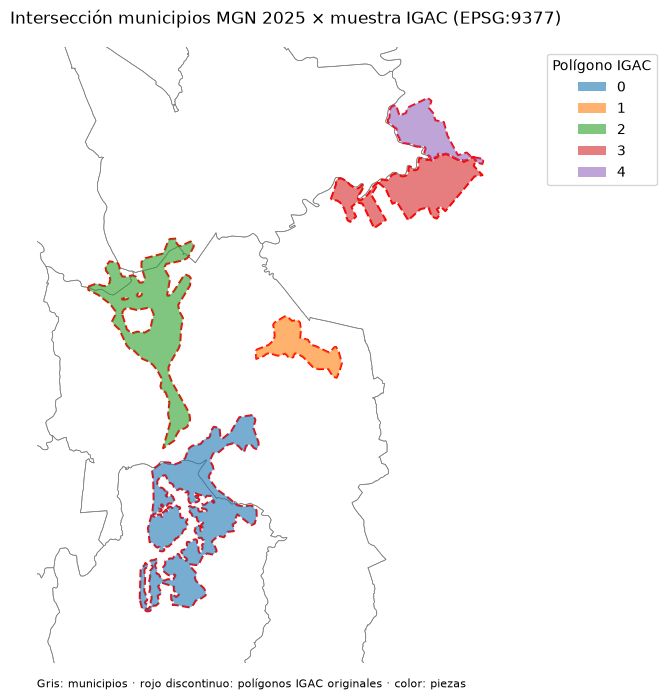

In [14]:
# 8. Intersección espacial con la muestra IGAC
municipios_m = municipios_validos[["codigo_municipio", "geometry"]].to_crs(epsg=9377)
atributos_igac = [c for c in capacidad_valida.columns
                  if c not in ("geometry", "id_igac") and any(p in c.lower() for p in ("clase", "capacidad", "uso", "descrip"))][:3]
print("Atributos IGAC conservados:", atributos_igac)
capacidad_m = capacidad_valida[["id_igac", *atributos_igac, "geometry"]].to_crs(epsg=9377)
capacidad_m = capacidad_m.rename(columns={c: "igac_" + c.lower() for c in atributos_igac})
# La reproyección puede volver inválida alguna geometría: se revisa y se repara de forma visible
for nombre_capa, capa in [("municipios_m", municipios_m), ("capacidad_m", capacidad_m)]:
    invalidas_m = ~capa.geometry.is_valid
    print(nombre_capa, "inválidas tras to_crs:", int(invalidas_m.sum()))
    if invalidas_m.any():
        capa.loc[invalidas_m, "geometry"] = capa.loc[invalidas_m].geometry.make_valid().apply(solo_poligonos)
assert municipios_m.is_valid.all() and capacidad_m.is_valid.all()
assert not set(municipios_m.columns).intersection(capacidad_m.columns) - {"geometry"}

piezas = gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)
print("Tipos resultantes:", piezas.geom_type.value_counts().to_dict())
piezas["area_m2"] = piezas.geometry.area
poligonal = piezas.geom_type.isin(["Polygon", "MultiPolygon"])
contactos = piezas[~poligonal | piezas["area_m2"].eq(0)]
print("Contactos de área cero (líneas/puntos):", len(contactos))
intersecciones = piezas[poligonal & piezas["area_m2"].gt(0)].copy()
intersecciones["area_ha"] = intersecciones.geometry.area / 10000
intersecciones = intersecciones.drop(columns="area_m2")
print("Piezas:", len(intersecciones), "| área total (ha):", round(intersecciones["area_ha"].sum(), 2))

# Riesgo de doble conteo: ¿se solapan los polígonos IGAC entre sí?
area_igac_suma = capacidad_m.geometry.area.sum() / 10000
area_igac_union = capacidad_m.geometry.union_all().area / 10000
print(f"IGAC: suma de áreas {area_igac_suma:,.2f} ha vs área de la unión {area_igac_union:,.2f} ha"
      f" → solapamiento {area_igac_suma - area_igac_union:,.2f} ha")

# Control por polígono IGAC: área original vs suma intersectada
control_igac = pd.DataFrame({"id_igac": capacidad_m["id_igac"],
                             "area_original_ha": capacidad_m.geometry.area / 10000})
control_igac = control_igac.merge(intersecciones.groupby("id_igac")["area_ha"].sum()
                                  .rename("area_intersectada_ha").reset_index(), on="id_igac", how="left")
control_igac["area_intersectada_ha"] = control_igac["area_intersectada_ha"].fillna(0)
control_igac["fuera_de_municipios_ha"] = control_igac["area_original_ha"] - control_igac["area_intersectada_ha"]
TOL = 0.001  # 0,1 % del área original
control_igac["dentro_de_municipios"] = control_igac["fuera_de_municipios_ha"].abs() <= TOL * control_igac["area_original_ha"]
display(control_igac)

area_por_mun = (intersecciones.groupby("codigo_municipio")["area_ha"].sum()
                .rename("area_intersectada_ha").reset_index())
mapa_municipal = mapa_municipal.merge(area_por_mun, on="codigo_municipio", how="left", validate="one_to_one")
assert len(mapa_municipal) == len(municipios_validos)
print("Municipios con área intersectada:", int(mapa_municipal["area_intersectada_ha"].notna().sum()))

# Mapa en la extensión de la muestra
xmin, ymin, xmax, ymax = capacidad_m.total_bounds
margen = 0.1 * max(xmax - xmin, ymax - ymin)
fig, ax = plt.subplots(figsize=(9, 8))
municipios_m.cx[xmin - margen:xmax + margen, ymin - margen:ymax + margen].plot(
    ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)
capacidad_m.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=1.5, linestyle="--")
intersecciones.plot(ax=ax, column="id_igac", categorical=True, alpha=0.6, legend=True,
                    legend_kwds={"title": "Polígono IGAC", "loc": "upper left", "bbox_to_anchor": (1.01, 1)})
ax.set_xlim(xmin - margen, xmax + margen); ax.set_ylim(ymin - margen, ymax + margen)
ax.set_title("Intersección municipios MGN 2025 × muestra IGAC (EPSG:9377)")
ax.set_axis_off()
ax.text(0, -0.04, "Gris: municipios · rojo discontinuo: polígonos IGAC originales · color: piezas",
        transform=ax.transAxes, fontsize=8)
plt.savefig(OUT + "/mapa_interseccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

La intersección (`overlay`) recorta cada polígono IGAC con los límites municipales según su forma y posición; un `merge`, en cambio, solo une atributos por un código. Separé los contactos de área cero (bordes compartidos) y calculé las hectáreas de cada pieza a partir de su propia geometría proyectada, no del atributo de área original. Por cada polígono IGAC comparo el área original con la suma de sus piezas: la diferencia es la parte que queda fuera de los municipios aptos. Si los polígonos IGAC se solapan entre sí, sumar sus áreas cuenta dos veces la misma superficie, así que esa suma no es una cobertura única. Cinco polígonos son una muestra: no permiten conocer la capacidad de uso de un municipio completo ni asignar una clase a una muestra AGROSAVIA.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [15]:
# 9. Publicación y relectura
COLUMNAS_ORIGINALES = list(suelo_original.columns)
COLUMNAS_CONTRATO = ["id_fila", "fecha_dt", "anio", "ph", "ph_valido", "departamento_norm", "municipio_norm",
                     "codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
                     "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial",
                     "estado_union_inicial", "estado_union"]
analisis_integrados = integrado[COLUMNAS_ORIGINALES + COLUMNAS_CONTRATO].copy()
analisis_integrados = analisis_integrados.astype({
    "id_fila": "Int64", "anio": "Int64", "ph": "Float64", "ph_valido": "boolean",
    "departamento_norm": "string", "municipio_norm": "string",
    "codigo_departamento": "string", "codigo_municipio": "string",
    "nombre_departamento_divipola": "string", "nombre_municipio_divipola": "string",
    "longitud_territorial": "Float64", "latitud_territorial": "Float64",
    "estado_union_inicial": "string", "estado_union": "string"})
analisis_integrados["fuente_analisis"] = pd.array(["agrosavia.csv"] * len(analisis_integrados), dtype="string")
analisis_integrados["fuente_territorial"] = pd.array(["divipola.csv (2024)"] * len(analisis_integrados), dtype="string")
analisis_integrados = analisis_integrados.sort_values("id_fila").reset_index(drop=True)
assert len(analisis_integrados) == N_SUELO

RUTA_PARQUET = OUT + "/analisis_integrados.parquet"
analisis_integrados.to_parquet(RUTA_PARQUET, engine="pyarrow", compression="snappy", index=False)
releido = pd.read_parquet(RUTA_PARQUET, engine="pyarrow")
pd.testing.assert_frame_equal(releido.sort_values("id_fila").reset_index(drop=True), analisis_integrados)
print("Parquet releído idéntico:", releido.shape)

# Controles y tablas auxiliares en CSV
controles = pd.DataFrame([
    {"control": "filas_entrada_agrosavia", "valor": N_SUELO},
    {"control": "filas_publicadas", "valor": len(releido)},
    {"control": "id_fila_unicos", "valor": int(releido["id_fila"].nunique())},
    {"control": "ph_valido", "valor": int(releido["ph_valido"].sum())},
    {"control": "fecha_no_interpretable", "valor": int(releido["fecha_dt"].isna().sum())},
    {"control": "asociados_a_municipio", "valor": int(releido["codigo_municipio"].notna().sum())},
    {"control": "filas_divipola", "valor": N_TERRITORIO},
    {"control": "poligonos_dane_aptos", "valor": len(municipios_validos)},
    {"control": "piezas_interseccion", "valor": len(intersecciones)},
])
controles.to_csv(OUT + "/controles.csv", index=False)
control_geometrias.to_csv(OUT + "/control_crs_geometrias.csv", index=False)
equivalencias.to_csv(OUT + "/equivalencias.csv", index=False)
resumen_municipal.to_csv(OUT + "/resumen_municipal.csv", index=False)
pd.concat([conciliacion.assign(tabla="resumen"), conciliacion_mapa.assign(tabla="mapa")]).to_csv(
    OUT + "/conciliacion.csv", index=False)
releido[releido["codigo_municipio"].isna()][["id_fila", "Departamento", "Municipio", "estado_union"]].to_csv(
    OUT + "/registros_pendientes.csv", index=False)
display(controles)

# GeoPackage nuevo en cada ejecución (sin append)
RUTA_GPKG = OUT + "/resultados_espaciales.gpkg"
if os.path.exists(RUTA_GPKG):
    os.remove(RUTA_GPKG)
mapa_municipal["_merge"] = mapa_municipal["_merge"].astype(str)
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
capa_mun = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")
capa_int = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="intersecciones", engine="pyogrio")
assert len(capa_mun) == len(mapa_municipal) and len(capa_int) == len(intersecciones)
assert capa_mun.crs == mapa_municipal.crs and capa_int.crs == intersecciones.crs
assert capa_mun["codigo_municipio"].astype(str).tolist() == mapa_municipal["codigo_municipio"].astype(str).tolist()
assert np.allclose(capa_mun["total_analisis"].astype(float).fillna(-1), mapa_municipal["total_analisis"].astype(float).fillna(-1))
assert np.allclose(capa_int["area_ha"], intersecciones["area_ha"], rtol=1e-9, atol=1e-6)
assert np.allclose(capa_int.geometry.area / 10000, intersecciones["area_ha"], rtol=1e-6)
print("GeoPackage releído: municipios", capa_mun.shape, capa_mun.crs, "| intersecciones", capa_int.shape, capa_int.crs)
print("Tipos restaurados por GPKG (municipios):")
print(capa_mun.dtypes.astype(str).to_dict())

Parquet releído idéntico: (92738, 49)


,control,valor
0,filas_entrada_agrosavia,92738
1,filas_publicadas,92738
2,id_fila_unicos,92738
3,ph_valido,92727
4,fecha_no_interpretable,0
5,asociados_a_municipio,90698
6,filas_divipola,1122
7,poligonos_dane_aptos,1122
8,piezas_interseccion,9


GeoPackage releído: municipios (1122, 20) EPSG:4326 | intersecciones (9, 5) EPSG:9377
Tipos restaurados por GPKG (municipios):
{'dpto_ccdgo': 'object', 'mpio_ccdgo': 'object', 'mpio_cdpmp': 'object', 'dpto_cnmbr': 'object', 'mpio_cnmbr': 'object', 'mpio_crslc': 'object', 'mpio_tipo': 'object', 'mpio_narea': 'float64', 'mpio_nano': 'int32', 'shape_Leng': 'float64', 'shape_Area': 'float64', 'codigo_municipio': 'object', 'total_analisis': 'float64', 'ph_validos': 'float64', 'media_ph': 'float64', 'anio': 'float64', '_merge': 'object', 'area_ha': 'float64', 'area_intersectada_ha': 'float64', 'geometry': 'geometry'}


**Interpretación:**

El Parquet tiene todas las filas, las columnas originales, los tipos del contrato, los indicadores y la procedencia. Al releerlo es idéntico al original ordenado por `id_fila` (`assert_frame_equal`). Los códigos siguen siendo texto con ceros iniciales, y los que no se resolvieron quedan ausentes. El GeoPackage se crea de nuevo en cada ejecución, con dos capas separadas; al releerlo coinciden filas, claves, CRS y áreas. GeoPackage puede devolver tipos distintos (por ejemplo, enteros nullable como `float`), y por eso comparo valores con tolerancia.

### Conclusiones
1. **Calidad de la fuente:** casi todos los análisis tienen pH y fecha válidos; los pocos pH no convertibles son valores censurados (`<3.80`, `>10.00`) o errores de digitación, y se conservan marcados en vez de borrarse.
2. **Enlace territorial:** la mayoría de los análisis se enlaza por nombre con DIVIPOLA; los que no, se explican por claves incompletas, nombres distintos o cambios entre catálogos, y quedan en `registros_pendientes.csv` y `equivalencias.csv` para revisar.
3. **Integración espacial:** unir por código (`merge`) y cruzar por geometría (`overlay`) responden preguntas distintas. El mapa muestra dónde hay muestras, pero no la cobertura real de suelos, y la muestra IGAC de 5 polígonos solo ilustra la técnica.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
